# Ranked pair strategy: 2026 analysis

Trade the validated pool in `data/pair_pool.csv`, ranked by 2025 Sharpe. Keep at most 15 active pairs. Each pair can trade only once; after an exit, scan the remaining unused pairs from the highest rank. All strategy and accounting logic is in `pair_backtest.py`. Results stay in memory; this notebook saves no extra CSV.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from pair_backtest import PairBacktestConfig, PairPoolBacktester
from risk import BetaAnalysis, RiskAnalysis

max_pairs = 15
long_amount = 1_000_000
start_date = "2026-01-01"
end_date = None  # Completed sessions; include today only after 17:00 New York time
allow_shared_tickers = False
borrow_fee_rate = 0.0
transaction_cost_rate = 0.0

config = PairBacktestConfig(
    max_pairs=max_pairs,
    long_amount=long_amount,
    start_date=start_date,
    end_date=end_date,
    allow_shared_tickers=allow_shared_tickers,
    borrow_fee_rate=borrow_fee_rate,
    transaction_cost_rate=transaction_cost_rate,
)
backtester = PairPoolBacktester.from_csv(Path("data/pair_pool.csv"), config)
print(f"Maximum active pairs: {max_pairs}")
print(f"strict_one_leg entry cap per pair side: ${config.leg_cap:,.2f}")
print(f"Fixed reference budget, including cash: ${2 * long_amount:,.2f}")
display(backtester.pairs[["rank", "pair_id", "validation_sharpe", "entry_z", "exit_z"]].head(15))

Maximum active pairs: 15
strict_one_leg entry cap per pair side: $66,666.67
Fixed reference budget, including cash: $2,000,000.00


,rank,pair_id,validation_sharpe,entry_z,exit_z
0,1,TSCO__DKS,3.168773,1.75,0.875
1,2,IOT__FICO,2.447722,0.75,0.375
2,3,IJH__MDY,2.437557,2.25,1.125
3,4,APO__AMP,2.376741,0.25,0.125
4,5,PSA__UDR,2.256158,2.75,1.375
5,6,CW__EMBJ,2.130160,1.50,0.750
6,7,IVE__IUSV,1.974488,1.25,0.625
7,8,VTI__ITOT,1.926911,0.50,0.250
8,9,VICI__GLPI,1.841946,0.75,0.375
9,10,SAP__CHKP,1.819871,1.00,0.500


## Trading rules

- Use `refit_alpha`, `refit_beta`, `refit_mu_e` and `refit_sigma_eq`, fitted through 2025 and frozen for 2026. The original fixed `mean_square` method and selected Z thresholds remain; no rolling z-score window or 2026 fitting is used.
- A Close entry signal fills at the next trading Open. The final 2025 Close can generate the first 2026 entry. January 1 need not be a trading day. High z shorts Y/longs X; low z reverses the direction.
- Entry sizing uses one common `strict_one_leg` scale, then rounds down to whole shares: each leg is at most `long_amount / max_pairs`. Actual long dollars can be lower after scaling/rounding. Limits apply at entry; fixed shares can drift above them as prices move.
- Close both legs when z reaches/crosses the exit threshold or the saved 12% trade stop triggers, using the following Open. Execute exits before new entries, then fill available slots by rank. Missing execution prices delay an exit or skip an entry. A used pair never returns. Tickers can be used by later pairs, but by default cannot overlap between simultaneous pairs.
- Leave unused capital in cash; fewer than 15 positions is allowed. `unused_pairs` shows pool depletion. Remaining holdings stay open at the final date, so final P&L includes realized and unrealized amounts.
- Fees, borrow, financing and distributions remain zero. Cumulative return is total P&L divided by the fixed USD 2 million reference budget. SPY is a price-return benchmark from the first session's Open. Tax deductions and after-tax returns are not calculated.

In [2]:
result = backtester.run()
daily_summary = result["daily_summary"]
daily_positions_long = result["daily_positions_long"]
daily_positions_short = result["daily_positions_short"]
events = result["events"]
closed_trades = result["closed_trades"]
open_positions = result["open_positions"]

print("Backtest dates:", daily_summary.index[0].date(), "to", daily_summary.index[-1].date())
print("Opened pairs:", events["event"].eq("open").sum())
print("Closed pairs:", len(closed_trades))
print("Remaining active pairs:", len(open_positions))
print("Unused eligible pairs:", daily_summary["unused_pairs"].iloc[-1])
print("Missing tickers:", result["missing_tickers"])
print("Source events:", result["source_events"][:10])
display(daily_summary.tail().round(2))

Backtest dates: 2026-01-02 to 2026-10-22
Opened pairs: 51
Closed pairs: 36
Remaining active pairs: 15
Unused eligible pairs: 111
Missing tickers: []
Source events: []


,active_pairs,used_pairs,unused_pairs,long_amount,short_amount,gross_amount,net_amount,cash,equity,long_pnl,...,realized_gain,realized_loss,cumulative_realized_gain,cumulative_realized_loss,cumulative_realized_pnl,unrealized_pnl,stale_price_legs,spy_close,spy_return,spy_cumulative_return
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-16,15,51,111,826261.69,-947537.11,1773798.80,-121275.42,2055803.06,1934527.64,4253.00,...,0.0,0.0,180950.66,-236287.72,-55337.06,-10135.30,0,763.25,-0.01,0.11
2026-10-19,15,51,111,820898.03,-941740.79,1762638.82,-120842.75,2055803.06,1934960.31,-5363.65,...,0.0,0.0,180950.66,-236287.72,-55337.06,-9702.63,0,766.48,0.00,0.12
2026-10-20,15,51,111,829000.46,-949215.35,1778215.81,-120214.89,2055803.06,1935588.17,8102.43,...,0.0,0.0,180950.66,-236287.72,-55337.06,-9074.77,0,769.05,0.00,0.12
2026-10-21,15,51,111,830598.26,-948658.11,1779256.37,-118059.85,2055803.06,1937743.22,1597.80,...,0.0,0.0,180950.66,-236287.72,-55337.06,-6919.72,0,773.09,0.01,0.13
2026-10-22,15,51,111,840475.03,-956541.89,1797016.92,-116066.86,2055803.06,1939736.20,9876.77,...,0.0,0.0,180950.66,-236287.72,-55337.06,-4926.74,0,763.96,-0.01,0.11


<Axes: title={'center': 'Active pairs and unused candidates'}, xlabel='Date'>

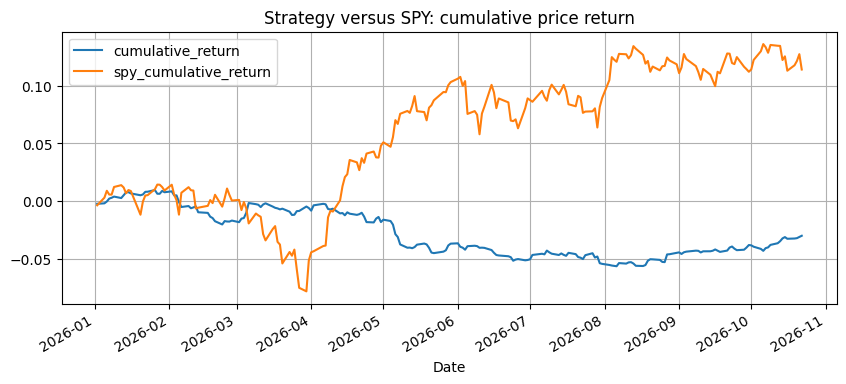

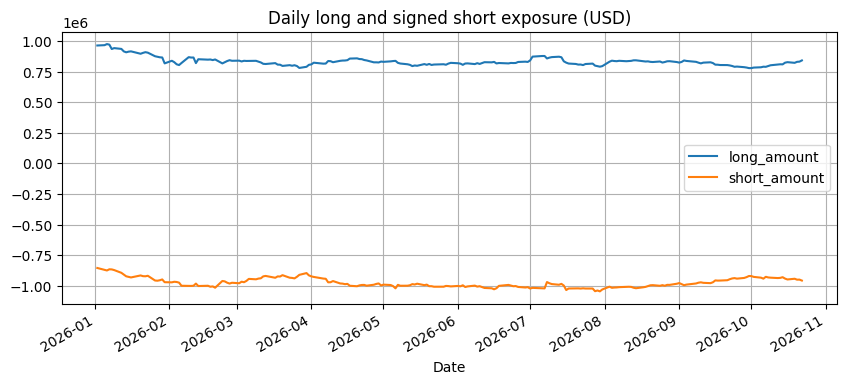

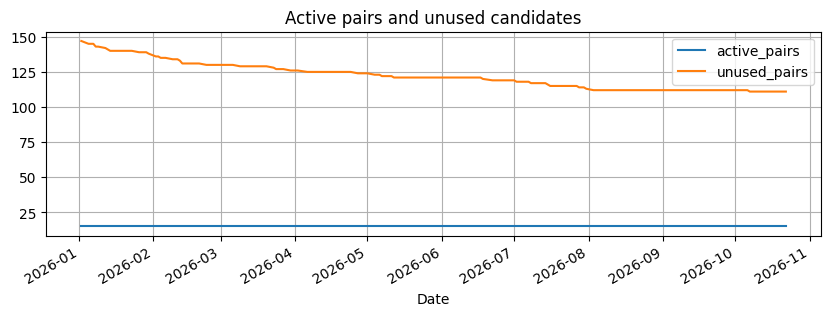

In [3]:
daily_summary[["cumulative_return", "spy_cumulative_return"]].plot(
    figsize=(10, 4), title="Strategy versus SPY: cumulative price return", grid=True,
)
daily_summary[["long_amount", "short_amount"]].plot(
    figsize=(10, 4), title="Daily long and signed short exposure (USD)", grid=True,
)
daily_summary[["active_pairs", "unused_pairs"]].plot(
    figsize=(10, 3), title="Active pairs and unused candidates", grid=True,
)

## Entries, exits and current holdings

Short shares and amounts are negative. `signal_date` is the prior Close that triggered the trade; `execution_date` is the actual Open fill. `rank` is the saved validation-Sharpe rank. Each close reports the two legs' realized P&L separately.

In [4]:
event_columns = [
    "execution_date", "signal_date", "event", "rank", "pair_id",
    "long_ticker", "short_ticker", "long_shares", "short_shares",
    "long_amount", "short_amount", "realized_pnl", "reason",
]
display(events[event_columns].head(30).round(2))
display(events[event_columns].tail(15).round(2))
holding_columns = [
    "entry_date", "rank", "pair_id", "long_ticker", "short_ticker",
    "long_shares", "short_shares", "long_amount", "short_amount", "unrealized_pnl", "z_score",
]
display(open_positions[holding_columns].round(4))

,execution_date,signal_date,event,rank,pair_id,long_ticker,short_ticker,long_shares,short_shares,long_amount,short_amount,realized_pnl,reason
0,2026-01-02,2025-12-31,open,1,TSCO__DKS,TSCO,DKS,1334,-163,66659.98,-32433.74,0.00,z_entry
1,2026-01-02,2025-12-31,open,2,IOT__FICO,IOT,FICO,1857,-38,66666.30,-64259.14,0.00,z_entry
2,2026-01-02,2025-12-31,open,3,IJH__MDY,IJH,MDY,1001,-110,66346.28,-66646.80,0.00,z_entry
3,2026-01-02,2025-12-31,open,4,APO__AMP,AMP,APO,136,-361,66640.00,-52348.61,0.00,z_entry
4,2026-01-02,2025-12-31,open,5,PSA__UDR,PSA,UDR,257,-1254,66588.70,-45858.78,0.00,z_entry
5,2026-01-02,2025-12-31,open,7,IVE__IUSV,IUSV,IVE,648,-310,66569.04,-65868.80,0.00,z_entry
6,2026-01-02,2025-12-31,open,8,VTI__ITOT,ITOT,VTI,443,-197,66241.79,-66418.55,0.00,z_entry
7,2026-01-02,2025-12-31,open,9,VICI__GLPI,VICI,GLPI,2367,-1364,66654.72,-60793.48,0.00,z_entry
8,2026-01-02,2025-12-31,open,10,SAP__CHKP,CHKP,SAP,357,-189,66312.75,-45824.94,0.00,z_entry
9,2026-01-02,2025-12-31,open,11,FIX__STRL,STRL,FIX,172,-71,53221.96,-66626.40,0.00,z_entry


,execution_date,signal_date,event,rank,pair_id,long_ticker,short_ticker,long_shares,short_shares,long_amount,short_amount,realized_pnl,reason
72,2026-07-02,2026-07-01,open,51,WM__WCN,WCN,WM,362,-295,60026.84,-66537.25,0.00,z_entry
73,2026-07-08,2026-07-07,close,48,BAC__EWBC,BAC,EWBC,1172,-483,69581.64,-62852.79,1716.96,z_exit
74,2026-07-08,2026-07-07,open,52,OTIS__IR,OTIS,IR,919,-450,66636.69,-34965.00,0.00,z_entry
75,2026-07-15,2026-07-14,close,41,HEI__FTAI,HEI,FTAI,246,-258,85676.88,-55439.04,26730.06,z_exit
76,2026-07-15,2026-07-14,open,53,AMAT__DELL,DELL,AMAT,114,-109,52377.30,-66531.42,0.00,z_entry
77,2026-07-16,2026-07-15,close,45,BLK__SYF,BLK,SYF,62,-634,68878.28,-46877.96,3217.49,z_exit
78,2026-07-16,2026-07-15,open,54,PWR__EME,EME,PWR,57,-105,42705.54,-66537.45,0.00,z_entry
79,2026-07-28,2026-07-27,close,53,AMAT__DELL,DELL,AMAT,114,-109,45743.64,-53510.28,6387.48,z_exit
80,2026-07-28,2026-07-27,open,55,CCI__SUI,CCI,SUI,372,-541,27914.88,-66543.00,0.00,z_entry
81,2026-07-31,2026-07-30,close,44,CPAY__IOT,IOT,CPAY,831,-216,29724.87,-83451.60,-11708.28,stop


,entry_date,rank,pair_id,long_ticker,short_ticker,long_shares,short_shares,long_amount,short_amount,unrealized_pnl,z_score
3030,2026-01-02,9,VICI__GLPI,VICI,GLPI,2367,-1364,56855.3411,-54587.2806,-3593.1796,-7.7732
3031,2026-01-02,12,USB__KEY,KEY,USB,2139,-1250,45368.1880,-75025.0006,-7121.8784,19.0725
3032,2026-01-02,16,SPGI__MCO,SPGI,MCO,135,-107,61168.5008,-52542.3487,-3479.3625,-15.0979
3033,2026-02-02,28,ITW__GGG,GGG,ITW,593,-255,41083.0393,-71206.1975,-15259.7291,31.7974
3034,2026-02-12,32,EPD__MPLX,MPLX,EPD,652,-1880,37933.3602,-68657.6009,-355.5188,11.5380
3035,2026-03-23,36,HBAN__RF,HBAN,RF,3660,-2536,57315.5994,-72022.3990,-4937.1177,-16.6154
3036,2026-03-24,39,SPYM__SCHX,SCHX,SPYM,2575,-869,77327.2518,-78149.1703,-519.3172,22.2599
3037,2026-05-04,43,ALL__WRB,WRB,ALL,888,-309,67088.4027,-80061.9019,-4978.8543,11.3714
3042,2026-07-31,47,CRM__CPAY,CRM,CPAY,188,-171,47054.5187,-70966.7117,8746.0587,-22.2506
3038,2026-07-02,51,WM__WCN,WCN,WM,362,-295,66926.5618,-70534.5018,2902.4682,10.3793


In [5]:
long_tail = daily_positions_long.tail()
short_tail = daily_positions_short.tail()
display(long_tail.loc[:, long_tail.ne(0).any()].round(2))
display(short_tail.loc[:, short_tail.ne(0).any()].round(2))

ticker,VICI,KEY,SPGI,GGG,MPLX,HBAN,SCHX,CCI,WRB,CRM,WCN,OTIS,EME,AWK,V
Date,,,,,,,,,,,,,,,
2026-10-16,55861.20,42758.61,58001.40,48620.07,37920.32,55888.2,77250.00,30600.72,66972.96,45251.60,60779.80,65552.27,41134.62,67200.12,72469.8
2026-10-19,54677.70,42608.88,57757.05,47884.75,37933.36,55741.8,77610.50,30154.32,65783.04,45580.60,59979.78,65285.76,40857.03,66517.86,72525.6
2026-10-20,55316.79,44512.59,59146.20,48086.37,38070.28,56876.4,77842.25,30184.08,64957.20,45576.84,61351.76,66232.33,40041.36,67623.42,73182.6
2026-10-21,54796.05,44983.17,59826.60,48513.33,38102.88,57535.2,78331.50,29257.80,66013.92,45454.64,60917.36,66489.65,39852.69,67110.48,73413.0
2026-10-22,56855.34,45368.19,61168.50,41083.04,37933.36,57315.6,77327.25,29324.76,67088.40,47054.52,66926.56,69476.40,37643.37,71328.54,74581.2


ticker,GLPI,USB,MCO,EPD,MUFG,CPAY,ITW,RF,SPYM,ALL,WM,IR,PWR,SUI,WTRG
Date,,,,,,,,,,,,,,,
2026-10-16,-53577.92,-73412.5,-51902.49,-69221.6,-60651.36,-68372.64,-69431.40,-69613.2,-78062.27,-76594.92,-66923.70,-35001.0,-66345.30,-63881.28,-44545.53
2026-10-19,-52950.48,-72312.5,-51494.82,-69184.0,-60041.52,-68837.76,-68893.35,-68979.2,-78409.87,-76276.65,-66790.95,-34987.5,-64933.05,-63594.55,-44054.58
2026-10-20,-53386.96,-73862.5,-50862.45,-69522.4,-59487.12,-69829.56,-70117.35,-70627.6,-78670.57,-77222.19,-68360.35,-35365.5,-62580.00,-64611.63,-44709.18
2026-10-21,-52309.40,-73812.5,-51472.35,-68789.2,-60346.44,-69692.76,-70584.00,-71134.8,-79070.31,-77571.36,-67726.10,-35577.0,-63119.70,-63004.86,-44447.34
2026-10-22,-54587.28,-75025.0,-52542.35,-68657.6,-59348.52,-70966.71,-71206.20,-72022.4,-78149.17,-80061.90,-70534.50,-33349.5,-58006.20,-64844.26,-47240.30


## P&L and risk

Realized losses sum the losing **legs**, including a losing leg in an overall profitable pair. At every date, cumulative P&L equals cumulative realized P&L plus remaining unrealized P&L. VaR/CVaR below use dollar daily P&L. Market beta uses daily strategy/SPY returns, excluding the first Open-to-Close day.

In [6]:
pnl_columns = [
    "cumulative_realized_loss", "cumulative_realized_gain",
    "cumulative_realized_pnl", "unrealized_pnl", "cumulative_pnl",
]
display(daily_summary.iloc[-1][pnl_columns].to_frame("USD").round(2))
print(f"Strategy return on fixed budget: {daily_summary['cumulative_return'].iloc[-1]:.2%}")
print(f"SPY price return: {daily_summary['spy_cumulative_return'].iloc[-1]:.2%}")

risk_analysis = RiskAnalysis(daily_summary["daily_pnl"].iloc[1:], confidence=0.95)
display(risk_analysis.summary().round(2))

,USD
cumulative_realized_loss,-236287.72
cumulative_realized_gain,180950.66
cumulative_realized_pnl,-55337.06
unrealized_pnl,-4926.74
cumulative_pnl,-60263.80


Strategy return on fixed budget: -3.01%
SPY price return: 11.41%


,VaR,CVaR
Method,,
Historical,8189.28,10612.66
Parametric (normal),7639.14,9510.03


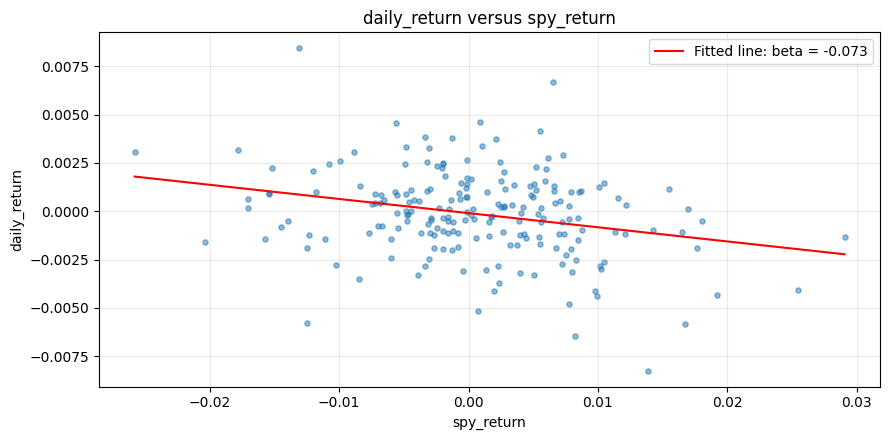

Alpha: -0.000094; beta: -0.0733


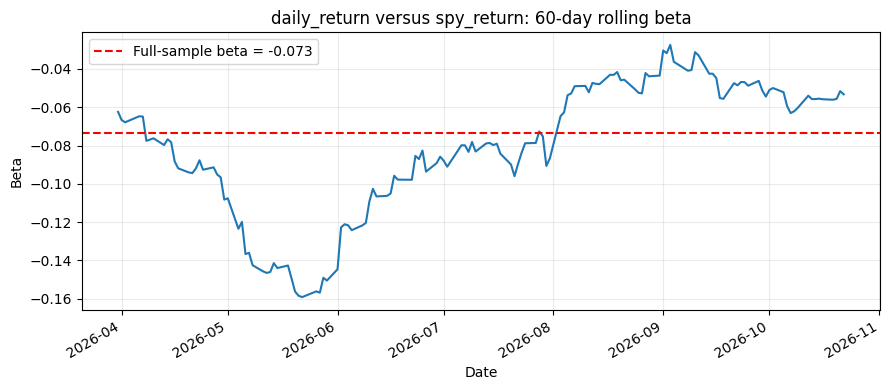

Latest rolling beta: -0.0532


In [7]:
beta_analysis = BetaAnalysis(
    x=daily_summary["spy_return"].iloc[1:],
    y=daily_summary["daily_return"].iloc[1:],
)
beta_analysis.plot_regression()
rolling_beta = beta_analysis.plot_rolling_beta(window=60)